### Importing the Dependencies

In [1]:
import numpy as np  
import pandas as pd  # Data manipulation
import matplotlib.pyplot as plt
import seaborn as sns # Visualization
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline  # Data splitting and preprocessing
from sklearn.svm import SVC # Machine Learning 
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, roc_auc_score) # Evaluation
import joblib # Save the trained model

### Data Collection and Analysis

In [2]:
# Loading the diabetes dataset to a pandas DataFrame
diabetes_dataset = pd.read_csv("data/raw/diabetes.csv")

In [ ]:
# pd.read_csv?

Signature:
pd.read_csv(
    filepath_or_buffer: 'FilePath | ReadCsvBuffer[bytes] | ReadCsvBuffer[str]',
    *,
    sep: 'str | None | lib.NoDefault' = <no_default>,
    delimiter: 'str | None | lib.NoDefault' = None,
    header: "int | Sequence[int] | None | Literal['infer']" = 'infer',
    names: 'Sequence[Hashable] | None | lib.NoDefault' = <no_default>,
    index_col: 'IndexLabel | Literal[False] | None' = None,
    usecols: 'UsecolsArgType' = None,
    dtype: 'DtypeArg | None' = None,
    engine: 'CSVEngine | None' = None,
    converters: 'Mapping[Hashable, Callable] | None' = None,
    true_values: 'list | None' = None,
    false_values: 'list | None' = None,
    skipinitialspace: 'bool' = False,
    skiprows: 'list[int] | int | Callable[[Hashable], bool] | None' = None,
    skipfooter: 'int' = 0,
    nrows: 'int | None' = None,
    na_values: 'Hashable | Iterable[Hashable] | Mapping[Hashable, Iterable[Hashable]] | None' = None,
    keep_default_na: 'bool' = True,
    na_filter: '

In [4]:
# printing the first 5 rows of the dataset
diabetes_dataset.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
# number of rows and columns in this dataset
diabetes_dataset.shape

(768, 9)

In [6]:
diabetes_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
diabetes_dataset.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [8]:
# getting the statistical measures of the data
diabetes_dataset.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [9]:
diabetes_dataset['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

- 0 --> Non-Diabetic
- 1 --> Diabetic

### Exploratory Data Analysis (EDA)

In [10]:
# Check missing values
diabetes_dataset.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [11]:
# Investigate zero values
columns_with_invalid_zeros = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

(diabetes_dataset[columns_with_invalid_zeros] == 0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

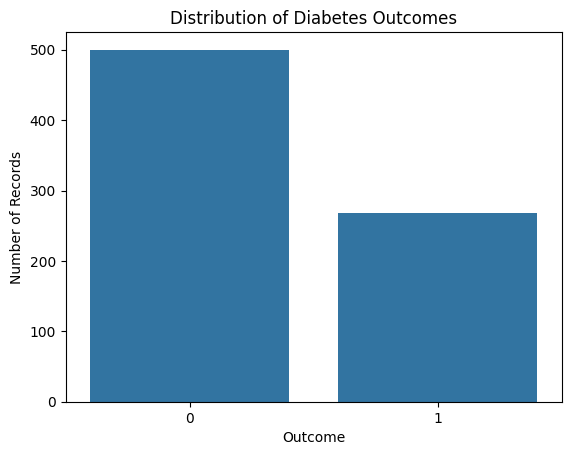

In [12]:
# Check the target distribution
sns.countplot(data=diabetes_dataset, x="Outcome")

plt.title("Distribution of Diabetes Outcomes")
plt.xlabel("Outcome")
plt.ylabel("Number of Records")

plt.show()

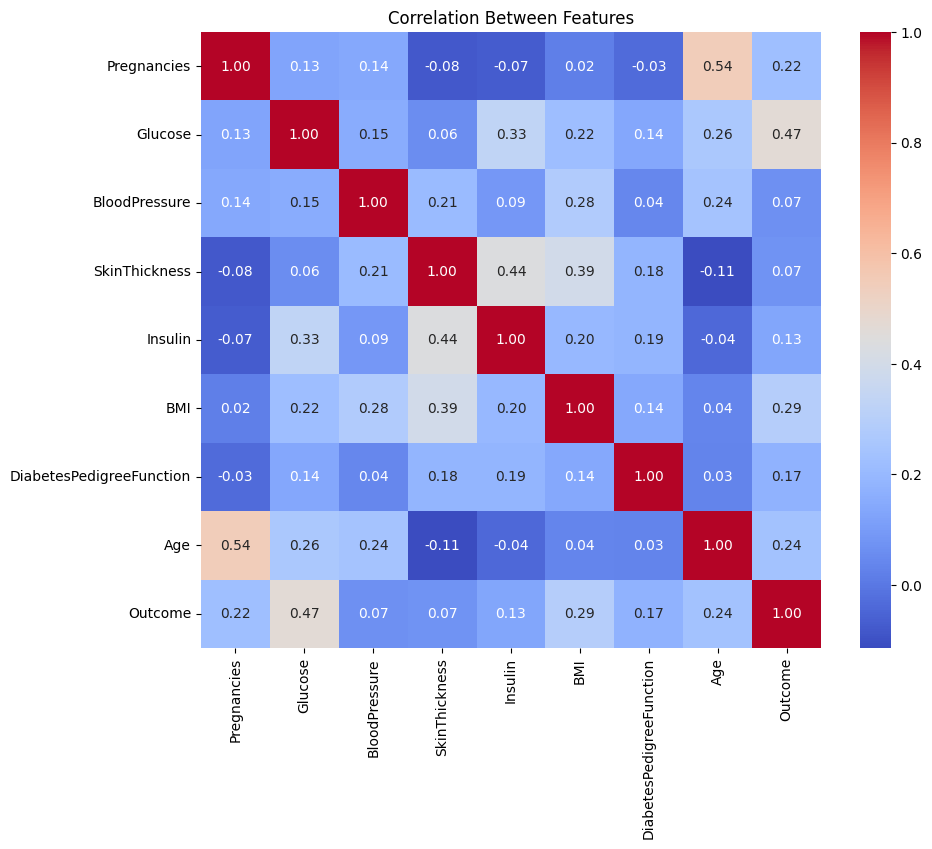

In [13]:
# Examine feature relationships
plt.figure(figsize=(10, 8))

sns.heatmap(
    diabetes_dataset.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Features")
plt.show()

### Data Preprocessing and Model Training

In [14]:
# Separate features and target
X = diabetes_dataset.drop(columns="Outcome")
y = diabetes_dataset["Outcome"]

In [15]:
# Identify invalid zero values
X = X.copy()

X[columns_with_invalid_zeros] = X[
    columns_with_invalid_zeros
].replace(0, np.nan)

In [16]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [17]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (614, 8)
Testing features: (154, 8)
Training target: (614,)
Testing target: (154,)


In [18]:
# Create the preprocessing and model pipeline
diabetes_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        SVC(kernel="linear", probability=True, random_state=42)
    )
])

In [19]:
# Train the model
diabetes_model.fit(X_train, y_train)

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


### Model Evaluation

In [20]:
# Training accuracy
y_train_pred = diabetes_model.predict(X_train)
training_accuracy = accuracy_score(y_train, y_train_pred)
print("Training Accuracy:", round(training_accuracy, 4))

Training Accuracy: 0.7866


In [21]:
# Testing accuracy
y_test_pred = diabetes_model.predict(X_test)
testing_accuracy = accuracy_score(y_test, y_test_pred)
print("Testing Accuracy:", round(testing_accuracy, 4))

Testing Accuracy: 0.7013


In [22]:
# Classification report
print(classification_report(y_test, y_test_pred, 
                            target_names=["Negative outcome", "Positive outcome"], zero_division=0))

                  precision    recall  f1-score   support

Negative outcome       0.75      0.82      0.78       100
Positive outcome       0.59      0.48      0.53        54

        accuracy                           0.70       154
       macro avg       0.67      0.65      0.66       154
    weighted avg       0.69      0.70      0.69       154



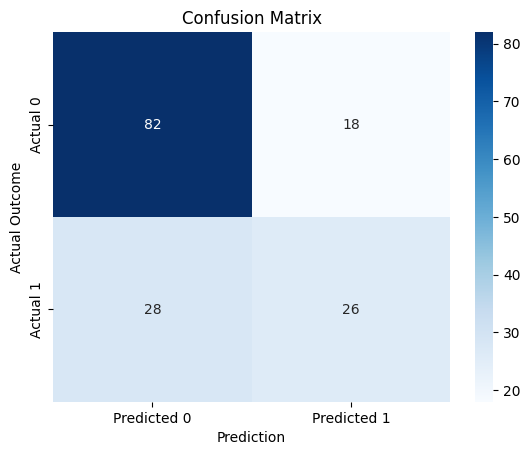

In [23]:
# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.title("Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual Outcome")

plt.show()

In [24]:
# ROC-AUC
y_test_prob = diabetes_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_test_prob)
print("ROC-AUC:", round(roc_auc, 4))

ROC-AUC: 0.8131


### Save the Trained Model

In [25]:
joblib.dump(
    diabetes_model,
    "models/diabetes_pipeline.joblib"
)

['models/diabetes_pipeline.joblib']

In [26]:
loaded_model = joblib.load(
    "models/diabetes_pipeline.joblib"
)

### Build the Interactive Prediction Application

In [27]:
%pip install gradio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
